Import Necessary Libraries

In [156]:
import pandas as pd
from pathlib import Path
import numpy as np
from PIL import Image
import cv2
import matplotlib.pyplot as plt

Data Exploration(Test Set)

In [157]:
df = pd.read_csv("EuroSAT/test.csv")

In [158]:
df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,2438,AnnualCrop/AnnualCrop_1275.jpg,0,AnnualCrop
1,1018,Residential/Residential_504.jpg,7,Residential
2,3,Pasture/Pasture_787.jpg,5,Pasture
3,1011,Residential/Residential_1575.jpg,7,Residential
4,47,Pasture/Pasture_473.jpg,5,Pasture


In [159]:
df.shape

(2700, 4)

In [160]:
counts = df['Label'].value_counts()

In [161]:
distribution = pd.DataFrame({'Count': counts})
print(distribution)

       Count
Label       
0        300
7        300
2        300
9        300
1        300
6        250
8        250
3        250
4        250
5        200


In [162]:
df.columns

Index(['Unnamed: 0', 'Filename', 'Label', 'ClassName'], dtype='object')

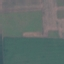

Format: JPEG, Size: (64, 64), Mode: RGB


In [163]:
with Image.open("EuroSAT/AnnualCrop/AnnualCrop_1275.jpg") as img:
    display(img)
    print(f"Format: {img.format}, Size: {img.size}, Mode: {img.mode}")

In [164]:
img_array = np.array(img)

In [165]:
img_array.shape

(64, 64, 3)

In [166]:
print("Data type:", img_array.dtype)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Data type: uint8
Minimum pixel value: 60
Maximum pixel value: 144


In [167]:
mean = 0
sigma =15

In [168]:
np.random.seed(42)

In [169]:
gaussian_noise = np.random.normal(mean, sigma, img_array.shape).astype(np.int16)

In [170]:
noisy_img = np.clip(img_array.astype(np.int16) + gaussian_noise, 0, 255).astype(np.uint8)

In [171]:
gaussian_noise_x = np.random.normal(mean, 10, img_array.shape).astype(np.int16)

In [172]:
noisy_img_x = np.clip(img_array.astype(np.int16) + gaussian_noise_x, 0, 255).astype(np.uint8)

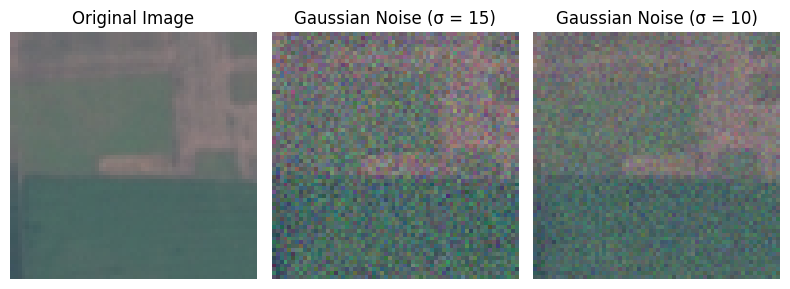

In [173]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_img)
plt.title("Gaussian Noise (σ = 15)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(noisy_img_x)
plt.title("Gaussian Noise (σ = 10)")
plt.axis("off")

plt.tight_layout()
plt.show()

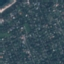

Format: JPEG, Size: (64, 64), Mode: RGB


In [174]:
with Image.open("EuroSAT/Residential/Residential_504.jpg") as img2:
    display(img2)
    print(f"Format: {img2.format}, Size: {img2.size}, Mode: {img2.mode}")

In [175]:
img_array2 = np.array(img2)

In [176]:
noisy_img_x2 = np.clip(img_array2.astype(np.int16) + gaussian_noise_x, 0, 255).astype(np.uint8)

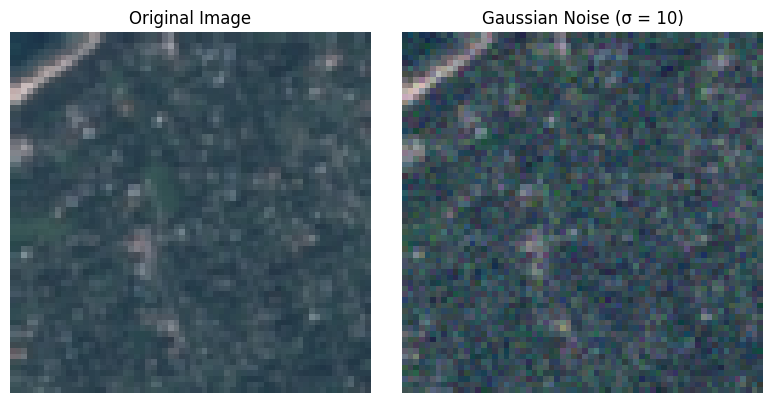

In [178]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img2)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_img_x2)
plt.title("Gaussian Noise (σ = 10)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [179]:
data_dir = Path("EuroSAT")

In [180]:
output_dir = Path("EuroSAT/transformed_test/gaussian_noise")

output_dir.mkdir(parents=True, exist_ok=True)

print("Output directory:", output_dir)
print("Directory exists:", output_dir.exists())

Output directory: EuroSAT/transformed_test/gaussian_noise
Directory exists: True


In [181]:
rng = np.random.default_rng(42)
mean = 0
sigma = 10

In [182]:
for filename in df["Filename"]:

    input_path = data_dir / filename
    output_path = output_dir / Path(filename).with_suffix(".jpg")
    all_img = cv2.imread(str(input_path))
    all_gaussian_noise = rng.normal(mean, sigma, all_img.shape)
    all_noisy_img = np.clip(
        img.astype(np.float32) + gaussian_noise_all_
        0,
        255
    ).astype(np.uint8)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(output_path), all_noisy_img)

print("Gaussian noise generation complete!")
print("Images processed:", len(df))


SyntaxError: invalid syntax. Perhaps you forgot a comma? (4116607078.py, line 8)

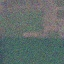

Format: JPEG, Size: (64, 64), Mode: RGB


In [184]:
with Image.open("EuroSAT/transformed_test/gaussian_noise/AnnualCrop/AnnualCrop_1275.jpg") as imgx:
    display(imgx)
    print(f"Format: {imgx.format}, Size: {imgx.size}, Mode: {imgx.mode}")

(np.float64(-0.5), np.float64(63.5), np.float64(63.5), np.float64(-0.5))

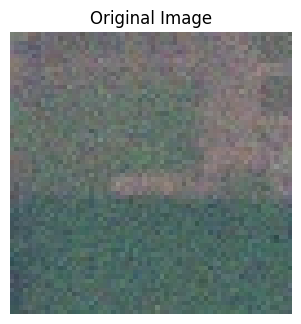

In [185]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(imgx)
plt.title("Original Image")
plt.axis("off")

In [186]:
blurred_img = cv2.GaussianBlur(
    img_array,
    (5,5),
    1.0
)


(np.float64(-0.5), np.float64(63.5), np.float64(63.5), np.float64(-0.5))

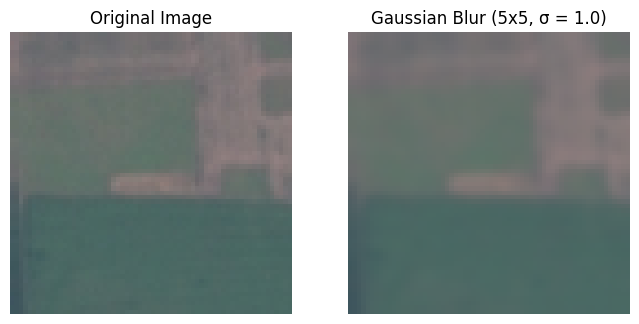

In [187]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_img)
plt.title("Gaussian Blur (5x5, σ = 1.0)")
plt.axis("off")

In [188]:
blur_output_dir = Path("EuroSAT/transformed_test/gaussian_blur")

# Select one test image
filename = df.iloc[0]["Filename"]

input_path = data_dir / filename
output_path = blur_output_dir / filename

# Load original image
img = cv2.imread(str(input_path))

# Apply Gaussian blur
blurred_img = cv2.GaussianBlur(img, (5, 5), 1.0)

# Create class folder
output_path.parent.mkdir(parents=True, exist_ok=True)

# Save as JPG
cv2.imwrite(
    str(output_path),
    blurred_img,
    [cv2.IMWRITE_JPEG_QUALITY, 100]
)

print("Saved successfully:", output_path.exists())

Saved successfully: True


In [189]:

# Gaussian blur parameters
kernel_size = (5, 5)
sigma = 1.0

# Loop through all test images
for filename in df["Filename"]:

    input_path = data_dir / filename
    output_path = blur_output_dir / filename

    # Load original image
    img = cv2.imread(str(input_path))

    # Apply Gaussian blur
    blurred_img = cv2.GaussianBlur(
        img,
        kernel_size,
        sigma
    )

    # Create class folder
    output_path.parent.mkdir(parents=True, exist_ok=True)

    # Save as JPG
    cv2.imwrite(
        str(output_path),
        blurred_img,
        [cv2.IMWRITE_JPEG_QUALITY, 100]
    )

print("Gaussian blur generation complete!")
print("Images processed:", len(df))


Gaussian blur generation complete!
Images processed: 2700
